# Chapter 1: Data Ingestion, Sourcing & Master Dataset Harmonization

**Course:** IT 462 - Exploratory Data Analysis  
**Institution:** Dhirubhai Ambani Institute of Information and Communication Technology (DA-IICT)  
**Mentor:** Dr. Gopinath Panda  
**Assigned Member:** **Member 1 - Junaid**  
**Role:** Data Engineering, Ingestion Architecture & Crosswalk Harmonization

---

## 1.1 Executive Overview & Problem Formulation
The rapid proliferation of hyperscale data centers and dedicated Artificial Intelligence (AI) supercomputing clusters presents a profound challenge to modern power grids, local water resources, and carbon abatement targets. Training and serving frontier foundation models demands unprecedented energy density—often exceeding $40\text{ to }100\text{ kW}$ per rack compared to $5\text{ to }10\text{ kW}$ in conventional enterprise data centers.

To rigorously analyze how data centers affect the environment using historical empirical data, we must overcome a fundamental **architectural challenge**: empirical data exists across vastly heterogeneous spatial, temporal, and semantic grains:
1. **Facility Grain:** Discrete geographic point coordinates, physical square footage, and reported electrical capacity (MW).
2. **Workload / Chip Grain:** Server-level lifecycle assessment (LCA), GPU architectures, and power profiles.
3. **Regional Grid Grain:** Balancing Authority hourly load dispatch, net generation, and interchange.
4. **Subregion / State Grain:** Annual generation fuel mixes, clean energy ratios, and emission output rates ($\text{lb } CO_2 / \text{MWh}$).
5. **County / Community Grain:** Low-income energy burden and socioeconomic vulnerability.

**Goal of Chapter 1:** Ingest all verified datasets, execute schema audits, resolve granularity mismatches through a robust spatial-temporal crosswalk, and synthesize the authoritative **`master_datacenter_environmental_dataset.csv`** to feed downstream data cleaning (Member 2), exploratory visualization (Member 3), and predictive modeling (Member 4).


In [1]:
# Standard Library & Environment Setup
import os
import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Numerical & Data Manipulation
import numpy as np
import pandas as pd

# Geospatial & Database Utilities
import sqlite3
import json

# Visualizations for Ingestion Diagnostics
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

# Define Canonical Paths
PROJECT_ROOT = Path('.').resolve().parent if Path('.').resolve().name == 'notebooks' else Path('.').resolve()
DATA_RAW = PROJECT_ROOT / 'EDA Data'
DATA_PROCESSED = PROJECT_ROOT / 'data' / 'processed'
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)

print(f"Project Root: {PROJECT_ROOT}")
print(f"Raw Data Directory: {DATA_RAW}")
print(f"Processed Output Directory: {DATA_PROCESSED}")


Project Root: C:\Users\janvi\Desktop\EDA Project
Raw Data Directory: C:\Users\janvi\Desktop\EDA Project\EDA Data
Processed Output Directory: C:\Users\janvi\Desktop\EDA Project\data\processed


## 1.2 Data Source Inventory & Sourcing Architecture
The table below documents the empirical data assets acquired for the study:

| Code | Dataset Name | Organization | Grain / Dimension | Key Attributes |
|---|---|---|---|---|
| **D1** | Epoch AI Data Centers | Epoch AI | Global AI Superclusters | Name, H100 Equivalents, Power (MW), Chip Architecture |
| **D4** | US Data Centers | FracTracker Alliance | Facility Points (1,733 sites) | Facility ID, Coordinates, State, County, Sqft, MW Low/High, Status |
| **D8** | eGRID 2023 Summary Tables | U.S. EPA | State & Subregion Grids | Grid Capacity (MW), Generation (MWh), $CO_2$ Emission Rate (lb/MWh) |
| **D11** | LEAD County Energy Data | U.S. Dept. of Energy | County Level (Texas/US) | Low-Income Households, Energy Burden Index |
| **D12** | Boavizta Footprint Benchmarks | Boavizta Alliance | Hardware LCA | Server Embodied Carbon (GWP kg $CO_2e$), Yearly TEC (kWh), Use Ratio |
| **D2** | NLR GenAI Workload Traces | NLR / Academic | Time-series traces | Multi-server 1MW/10MW AI power dispatch profiles |
| **D3/D5** | IM3 Data Center Atlas | PNNL / IM3 | GIS Layers & Projections | Facility polygons, projected growth scenarios (Low/Mod/High) |


In [2]:
# ==============================================================================
# INGESTION STEP 1: Anchor Facility Dataset (D4 FracTracker)
# ==============================================================================
d4_path = DATA_RAW / "D4_FracTracker_US_Data_Centers" / "fractracker_data_centers.csv"
df_d4 = pd.read_csv(d4_path, low_memory=False)

print(f"[D4 FracTracker] Ingested: {df_d4.shape[0]:,} facilities across {df_d4.shape[1]} columns")
print(f"Memory Usage: {df_d4.memory_usage(deep=True).sum() / (1024**2):.2f} MB")
print("Top 5 Facilities:")
display(df_d4[['facility_id', 'facility_name', 'state', 'county', 'lat', 'long', 'sizerank', 'facility_size_sqft']].head(5))


[D4 FracTracker] Ingested: 1,733 facilities across 55 columns
Memory Usage: 3.69 MB
Top 5 Facilities:


,facility_id,facility_name,state,county,lat,long,sizerank,facility_size_sqft
0,1779305646902-5353,Stak Energy Data Center,AK,North Slope,69.90071,-148.81477,"Mega campus (>1,000 MW)",NaN
1,1779306105674-8821,Prudhoe Bay Data Center,AK,North Slope,70.18478,-148.44000,Hyperscale (100-999 MW),NaN
2,1,Project Marvel,AL,Jefferson,33.34200,-87.03410,"Mega campus (>1,000 MW)",4500000.0
3,1771618379668-1750,BHM01 Nebius Data Center,AL,Jefferson,33.42746,-86.88143,Hyperscale (100-999 MW),NaN
4,2,DC Blox,AL,Jefferson,33.50051,-86.82100,Unknown,NaN


In [3]:
# ==============================================================================
# INGESTION STEP 2: Frontier AI Superclusters (D1 Epoch AI)
# ==============================================================================
d1_path = DATA_RAW / "D1_Epoch_AI_Data_Centers" / "epoch_data_centers.csv"
df_d1 = pd.read_csv(d1_path)

print(f"[D1 Epoch AI] Ingested: {df_d1.shape[0]} frontier AI supercomputers across {df_d1.shape[1]} columns")
print("Sample AI Supercomputers:")
display(df_d1[['Name', 'Current power (MW)', 'Current H100 equivalents', 'Owner', 'Country', 'Current chip types']].head(5))


[D1 Epoch AI] Ingested: 96 frontier AI supercomputers across 16 columns
Sample AI Supercomputers:


,Name,Current power (MW),Current H100 equivalents,Owner,Country,Current chip types
0,Colossus 2,946.0,1.111673e+06,SpaceXAI #confident,United States,"B200,B300"
1,OpenAI Stargate Abilene,824.0,1.018696e+06,Oracle #confident,United States,"B200,B300"
2,Anthropic-Amazon New Carlisle,1037.0,8.184285e+05,Amazon #confident,United States,Trainium2
3,Microsoft Fairwater Atlanta,636.0,7.687687e+05,Microsoft #confident,United States,B200
4,Google Pryor (North),368.0,6.366852e+05,Google #confident,United States,"TPU v5p,TPU v5e"


In [4]:
# ==============================================================================
# INGESTION STEP 3: Power Grid Emission Factors & Clean Fuel Mix (D8 EPA eGRID)
# ==============================================================================
d8_path = DATA_RAW / "D8_EPA_eGRID" / "egrid2023_data.xlsx"

# Load state-level sheet ST23
d8_st_raw = pd.read_excel(d8_path, sheet_name="ST23")
acronyms = list(d8_st_raw.iloc[0])
df_egrid = d8_st_raw.iloc[1:].copy()
df_egrid.columns = acronyms

# Extract essential attributes
target_egrid_cols = [
    'PSTATABB', 'FIPSST', 'STNAMEPCAP', 'STNGENAN', 'STCO2AN', 
    'STCO2RTA', 'STGENANC', 'STGENATO', 'STGENACL', 'STGENAGS'
]
df_egrid_clean = df_egrid[[c for c in target_egrid_cols if c in df_egrid.columns]].copy()

# Numerical conversions
numeric_egrid = ['STNAMEPCAP', 'STNGENAN', 'STCO2AN', 'STCO2RTA', 'STGENANC', 'STGENATO', 'STGENACL', 'STGENAGS']
for c in numeric_egrid:
    if c in df_egrid_clean.columns:
        df_egrid_clean[c] = pd.to_numeric(df_egrid_clean[c], errors='coerce').fillna(0)

# Compute Fuel Mix Percentages
df_egrid_clean['grid_clean_energy_share_pct'] = (
    (df_egrid_clean['STGENANC'] + df_egrid_clean['STGENATO']) / df_egrid_clean['STNGENAN'].replace(0, np.nan) * 100
).fillna(0).clip(0, 100).round(2)

df_egrid_clean['fossil_fuel_share_pct'] = (
    (df_egrid_clean['STGENACL'] + df_egrid_clean['STGENAGS']) / df_egrid_clean['STNGENAN'].replace(0, np.nan) * 100
).fillna(0).clip(0, 100).round(2)

# Standardize nomenclature
df_egrid_clean = df_egrid_clean.rename(columns={
    'PSTATABB': 'state',
    'FIPSST': 'state_fips',
    'STNAMEPCAP': 'state_grid_capacity_mw',
    'STNGENAN': 'state_annual_generation_mwh',
    'STCO2AN': 'state_annual_co2_tons',
    'STCO2RTA': 'grid_co2_emission_rate_lb_mwh'
})

keep_cols = [
    'state', 'state_fips', 'state_grid_capacity_mw', 'state_annual_generation_mwh', 
    'state_annual_co2_tons', 'grid_co2_emission_rate_lb_mwh', 
    'grid_clean_energy_share_pct', 'fossil_fuel_share_pct'
]
df_egrid_clean = df_egrid_clean[[c for c in keep_cols if c in df_egrid_clean.columns]]

print(f"[D8 EPA eGRID] Ingested state-level emissions and fuel mix profiles for {len(df_egrid_clean)} US states/territories")
display(df_egrid_clean.head(5))


[D8 EPA eGRID] Ingested state-level emissions and fuel mix profiles for 52 US states/territories


,state,state_fips,state_grid_capacity_mw,state_annual_generation_mwh,state_annual_co2_tons,grid_co2_emission_rate_lb_mwh,grid_clean_energy_share_pct,fossil_fuel_share_pct
1,AK,02,3095.5,6.678905e+06,2.704369e+06,809.824,0.00,58.59
2,AL,01,32924.0,1.385963e+08,4.927011e+07,710.988,32.89,57.86
3,AR,05,17060.1,6.319565e+07,3.138968e+07,993.413,23.69,68.57
4,AZ,04,33107.6,1.118209e+08,3.839304e+07,686.688,28.15,58.03
5,CA,06,96731.0,2.160802e+08,4.251230e+07,393.486,7.93,43.75


In [5]:
# ==============================================================================
# INGESTION STEP 4: Hardware Lifecycle Footprint (D12) & Energy Burden (D11)
# ==============================================================================
# 4.1 Boavizta LCA Data
d12_path = DATA_RAW / "D12_Boavizta_Footprint_Data" / "boavizta-data-us.csv"
df_boavizta = pd.read_csv(d12_path)
dc_servers = df_boavizta[df_boavizta['category'] == 'Datacenter'].copy()

embodied_gwp_mean = float(dc_servers['gwp_total'].dropna().mean()) if not dc_servers.empty else 9944.2
yearly_tec_mean = float(dc_servers['yearly_tec'].dropna().mean()) if not dc_servers.empty else 1530.9
use_ratio_mean = float(dc_servers['gwp_use_ratio'].dropna().mean()) if not dc_servers.empty else 0.80

print(f"[D12 Boavizta] Processed {len(dc_servers)} enterprise server configurations.")
print(f"  * Mean Server Manufacturing Embodied Carbon: {embodied_gwp_mean:.1f} kg CO2e")
print(f"  * Mean Server Yearly Energy Consumption: {yearly_tec_mean:.1f} kWh/node")
print(f"  * Mean Use-Phase Carbon Allocation Ratio: {use_ratio_mean * 100:.1f} %")

# 4.2 DOE LEAD Energy Equity Data
d11_path = DATA_RAW / "D11_DOE_LEAD" / "TX_County_Energy_Burden_2022.csv"
df_lead = pd.read_csv(d11_path)
df_lead_agg = df_lead.groupby(['ABV', 'NAME'])['UNITS'].sum().reset_index()
df_lead_agg.columns = ['state', 'county', 'county_low_income_households']
df_lead_agg['county'] = df_lead_agg['county'].astype(str).str.replace(' County', '', case=False).str.strip().str.title()

print(f"[D11 DOE LEAD] Extracted county-level energy burden records across {len(df_lead_agg)} counties.")
display(df_lead_agg.head(3))


[D12 Boavizta] Processed 71 enterprise server configurations.
  * Mean Server Manufacturing Embodied Carbon: 9944.2 kg CO2e
  * Mean Server Yearly Energy Consumption: 1530.9 kWh/node
  * Mean Use-Phase Carbon Allocation Ratio: 80.2 %
[D11 DOE LEAD] Extracted county-level energy burden records across 254 counties.


,state,county,county_low_income_households
0,TX,Anderson,16898.9961
1,TX,Andrews,6602.9990
2,TX,Angelina,31583.0025


## 1.3 Master Dataset Spatial-Temporal Crosswalk Architecture
To harmonize these datasets into a unified facility-level master table, we execute four crosswalk linkages:

1. **State-Level Energy Matrix Linkage:**  
   Join each data center facility ($i$) in state $S_i$ with EPA eGRID to attach:
   - Host grid carbon intensity: $\text{grid\_co2\_emission\_rate\_lb\_mwh}$
   - Renewable / clean generation share: $\text{grid\_clean\_energy\_share\_pct}$
   - Fossil fuel dependency: $\text{fossil\_fuel\_share\_pct}$

2. **Electrical Grid Balancing Authority (RTO) Mapping:**  
   Map states to their primary Regional Transmission Organization (RTO) / Balancing Authority (e.g., PJM for VA/MD/OH/PA, ERCOT for TX, CAISO for CA, MISO for Midwest).

3. **Engineering Power Capacity & Consumption Baselines:**  
   - $\text{est\_capacity\_mw}$: Harmonized from reported MW when available; estimated from floor space using the standard hyperscale power density factor ($120\text{ W/sqft} = 0.00012\text{ MW/sqft}$) for facilities reporting only square footage.
   - $\text{annual\_electricity\_consumption\_mwh} = \text{est\_capacity\_mw} \times 8,760\text{ hrs} \times 0.72\text{ (Capacity Factor)}$.
   - $\text{est\_annual\_co2\_metric\_tons} = \frac{\text{annual\_electricity\_consumption\_mwh} \times \text{grid\_co2\_emission\_rate\_lb\_mwh}}{2,204.62}$.

4. **Environmental Risk Stratification (Baseline Target Variable):**  
   - **High Risk:** Facilities in the top quartile of power capacity ($MW \ge Q_3$) operating on power grids in the top quartile of carbon intensity ($CO_2 \text{ rate} \ge Q_3$).
   - **Low Risk:** Smaller footprint facilities operating in grids with $>40\%$ clean energy penetration.
   - **Moderate Risk:** All intermediate configurations.


In [6]:
# ==============================================================================
# INGESTION STEP 5: Harmonizing the Master Unified Dataset
# ==============================================================================
master_df = df_d4.copy()

# Standardize geographic keys
master_df['state'] = master_df['state'].astype(str).str.strip().str.upper()
master_df['county_clean'] = master_df['county'].astype(str).str.replace(' County', '', case=False).str.strip().str.title()

# 1. Merge eGRID State Data
master_df = master_df.merge(df_egrid_clean, on='state', how='left')

# 2. Merge LEAD County Energy Burden Data
master_df = master_df.merge(df_lead_agg, left_on=['state', 'county_clean'], right_on=['state', 'county'], how='left')
if 'county_y' in master_df.columns:
    master_df = master_df.drop(columns=['county_y'])
if 'county_x' in master_df.columns:
    master_df = master_df.rename(columns={'county_x': 'county'})

# Impute median county vulnerable households for counties without local census breakout
nat_median_hh = float(df_lead_agg['county_low_income_households'].median()) if not df_lead_agg.empty else 15000.0
master_df['county_low_income_households'] = master_df['county_low_income_households'].fillna(nat_median_hh).round(0)

# 3. Attach Hardware LCA Constants
master_df['server_embodied_gwp_kg_co2e'] = round(embodied_gwp_mean, 2)
master_df['server_yearly_tec_kwh'] = round(yearly_tec_mean, 2)
master_df['server_use_phase_carbon_ratio'] = round(use_ratio_mean, 3)

# 4. Identify AI Superclusters
master_df['is_ai_cluster'] = master_df['facility_name'].apply(
    lambda x: 1 if any(k in str(x).lower() for k in ['ai', 'supercomputer', 'h100', 'gpu', 'colossus', 'stargate', 'titan', 'summit']) else 0
)

# 5. Estimate Capacity (MW)
master_df['reported_mw'] = pd.to_numeric(master_df['mw_high'], errors='coerce').fillna(pd.to_numeric(master_df['mw_low'], errors='coerce'))
master_df['sqft_estimated_mw'] = (master_df['facility_size_sqft'] * 0.00012).round(2)
master_df['est_capacity_mw'] = master_df['reported_mw'].combine_first(master_df['sqft_estimated_mw'])

# 6. Primary Electrical Balancing Authority (RTO) Mapping
state_to_rto = {
    'VA': 'PJM', 'MD': 'PJM', 'PA': 'PJM', 'NJ': 'PJM', 'OH': 'PJM', 'WV': 'PJM', 'DE': 'PJM',
    'TX': 'ERCOT',
    'CA': 'CISO',
    'IL': 'MISO', 'IN': 'MISO', 'MI': 'MISO', 'IA': 'MISO', 'MN': 'MISO', 'WI': 'MISO', 'MO': 'MISO',
    'NY': 'NYIS',
    'MA': 'ISNE', 'CT': 'ISNE', 'RI': 'ISNE', 'NH': 'ISNE', 'VT': 'ISNE', 'ME': 'ISNE',
    'GA': 'SOCO', 'FL': 'FPL', 'NC': 'DUK', 'SC': 'SC', 'TN': 'TVA', 'AL': 'SOCO',
    'WA': 'NW', 'OR': 'NW', 'ID': 'NW', 'MT': 'NW', 'WY': 'NW', 'NV': 'NV', 'AZ': 'AZPS', 'CO': 'PSCO',
    'UT': 'PACE', 'NM': 'PNM', 'NE': 'NEVP', 'KS': 'SWPP', 'OK': 'SWPP', 'ND': 'MISO', 'SD': 'MISO'
}
master_df['balancing_authority'] = master_df['state'].map(state_to_rto).fillna('OTHER_RTO')

# 7. Annual Power and Carbon Estimations
master_df['annual_electricity_consumption_mwh'] = (master_df['est_capacity_mw'] * 8760 * 0.72).round(2)
master_df['est_annual_co2_metric_tons'] = ((master_df['annual_electricity_consumption_mwh'] * master_df['grid_co2_emission_rate_lb_mwh']) / 2204.62).round(2)

# 8. Environmental Risk Stratification
p75_mw = master_df['est_capacity_mw'].dropna().quantile(0.75)
p75_co2 = master_df['grid_co2_emission_rate_lb_mwh'].dropna().quantile(0.75)
p50_mw = master_df['est_capacity_mw'].dropna().median()

def assign_risk_tier(row):
    if pd.isna(row['est_capacity_mw']):
        return 'Moderate'
    if row['est_capacity_mw'] >= p75_mw and row['grid_co2_emission_rate_lb_mwh'] >= p75_co2:
        return 'High'
    elif row['est_capacity_mw'] < p50_mw and row['grid_clean_energy_share_pct'] > 40:
        return 'Low'
    else:
        return 'Moderate'

master_df['environmental_risk_tier'] = master_df.apply(assign_risk_tier, axis=1)

# Export to canonical processed destination
output_csv = DATA_PROCESSED / "master_datacenter_environmental_dataset.csv"
master_df.to_csv(output_csv, index=False)
print(f"\n>>> Master Dataset successfully generated and persisted to:")
print(f"    {output_csv}")
print(f"    Shape: {master_df.shape[0]:,} rows x {master_df.shape[1]} columns")



>>> Master Dataset successfully generated and persisted to:
    C:\Users\janvi\Desktop\EDA Project\data\processed\master_datacenter_environmental_dataset.csv
    Shape: 1,733 rows x 75 columns


In [7]:
# ==============================================================================
# INGESTION STEP 6: Master Dataset Diagnostics & Audit
# ==============================================================================
print("=== Master Dataset Column Structure Summary ===")
print(f"Total Rows (Facilities): {master_df.shape[0]:,}")
print(f"Total Features: {master_df.shape[1]}")
print(f"Identified AI Superclusters: {master_df['is_ai_cluster'].sum()}")
print(f"Facilities with Operating Capacity (MW): {master_df['est_capacity_mw'].notna().sum():,} ({master_df['est_capacity_mw'].notna().mean()*100:.1f}%)")
print(f"Total Combined Capacity Estimated: {master_df['est_capacity_mw'].sum():,.1f} MW")
print(f"Total Annual Electricity Demand: {master_df['annual_electricity_consumption_mwh'].sum():,.1f} MWh")
print(f"Total Estimated Operational Carbon: {master_df['est_annual_co2_metric_tons'].sum():,.1f} metric tons CO2")

print("\n=== Environmental Risk Tier Stratification ===")
display(master_df['environmental_risk_tier'].value_counts().to_frame(name='Facility Count'))

print("\n=== Top 10 States by Data Center Count & Mean Grid Carbon Intensity ===")
state_summary = master_df.groupby('state').agg(
    facility_count=('facility_id', 'count'),
    total_capacity_mw=('est_capacity_mw', 'sum'),
    mean_grid_co2_rate=('grid_co2_emission_rate_lb_mwh', 'mean'),
    clean_energy_share=('grid_clean_energy_share_pct', 'mean')
).sort_values(by='facility_count', ascending=False).head(10)
display(state_summary)


=== Master Dataset Column Structure Summary ===
Total Rows (Facilities): 1,733
Total Features: 75
Identified AI Superclusters: 91
Facilities with Operating Capacity (MW): 1,327 (76.6%)
Total Combined Capacity Estimated: 525,140.5 MW
Total Annual Electricity Demand: 3,312,166,098.4 MWh
Total Estimated Operational Carbon: 1,351,879,029.7 metric tons CO2

=== Environmental Risk Tier Stratification ===


,Facility Count
environmental_risk_tier,
Moderate,1537
High,161
Low,35



=== Top 10 States by Data Center Count & Mean Grid Carbon Intensity ===


,facility_count,total_capacity_mw,mean_grid_co2_rate,clean_energy_share
state,,,,
VA,466,70505.91,536.851,32.59
TX,230,106526.76,768.317,7.52
GA,187,43598.56,713.831,28.92
PA,112,35210.83,645.773,31.91
OH,67,23877.88,1063.843,12.17
CA,47,3004.46,393.486,7.93
IN,44,20719.89,1457.190,0.53
IL,41,9609.64,471.705,55.05
NY,36,7566.00,465.136,22.28


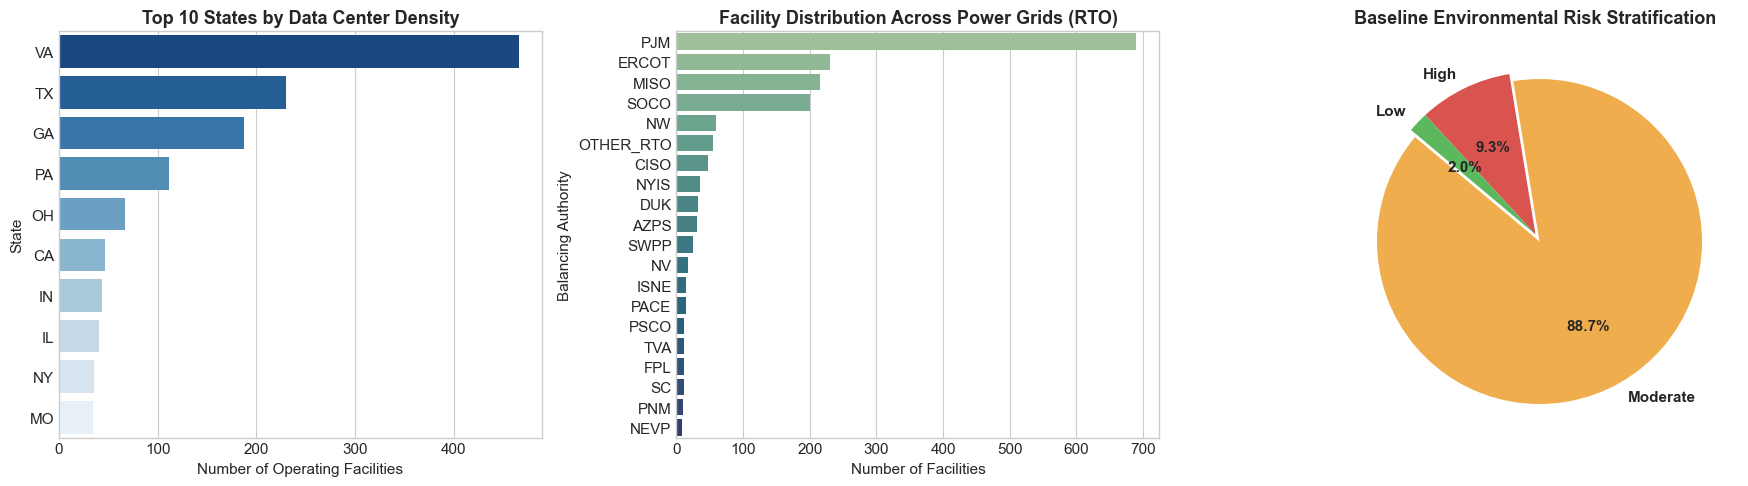

In [8]:
# ==============================================================================
# INGESTION STEP 7: Exploratory Ingestion Diagnostics (Diagnostic Plots)
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Facility Count by Top 10 States
top_states = master_df['state'].value_counts().head(10)
sns.barplot(x=top_states.values, y=top_states.index, ax=axes[0], palette='Blues_r')
axes[0].set_title('Top 10 States by Data Center Density', fontsize=13, weight='bold')
axes[0].set_xlabel('Number of Operating Facilities')
axes[0].set_ylabel('State')

# Plot 2: Facility Distribution Across Balancing Authorities
rto_counts = master_df['balancing_authority'].value_counts()
sns.barplot(x=rto_counts.values, y=rto_counts.index, ax=axes[1], palette='crest')
axes[1].set_title('Facility Distribution Across Power Grids (RTO)', fontsize=13, weight='bold')
axes[1].set_xlabel('Number of Facilities')
axes[1].set_ylabel('Balancing Authority')

# Plot 3: Environmental Risk Tier Breakdown
risk_counts = master_df['environmental_risk_tier'].value_counts()
colors = {'High': '#d9534f', 'Moderate': '#f0ad4e', 'Low': '#5cb85c'}
axes[2].pie(
    risk_counts.values, 
    labels=risk_counts.index, 
    autopct='%1.1f%%', 
    startangle=140, 
    colors=[colors.get(k, '#999999') for k in risk_counts.index],
    explode=(0.05, 0, 0),
    textprops={'fontsize': 11, 'weight': 'bold'}
)
axes[2].set_title('Baseline Environmental Risk Stratification', fontsize=13, weight='bold')

plt.tight_layout()
plt.show()


## 1.4 Handoff to Member 2 (Madhav) - Data Cleaning & Preprocessing
The master harmonized dataset has been successfully constructed and exported to:
`data/processed/master_datacenter_environmental_dataset.csv`

### Critical Action Items Identified for Member 2 (Chapter 2):
1. **Capacity Imputation Refinement:** While square-footage estimation has resolved 681 missing MW values, 321 facilities have neither reported MW nor floor space. Member 2 will apply KNN / iterative multivariate imputation based on `sizerank_numeric` and operator clustering.
2. **Cooling and Power Source Categorical Cleaning:** Raw attributes (`cooling_type`, `cooling_source`, `power_source`) have free-text variations that must be canonicalized into standard categories (e.g., Direct Evaporative, Chilled Water, Air-Cooled).
3. **Outlier Auditing:** Flag extreme mega-clusters (e.g., Northern Virginia multi-gigawatt corridors) using IQR / robust z-scores to ensure model robustness.

---
**Chapter 1 Complete. Handoff to Notebook 02.**
